# Project 3: Kerbl vs. factorized model (quick run)

Runs the Kerbl 3DGS baseline and our factorized model on the same scenes, then compares them.

**To run:** Runtime → Change runtime type → **A100** (fastest), **L4** or **T4** GPU, then Runtime → Run all. TPU and G4 won't work (the CUDA 11.8 build doesn't support them).

Quick settings: lego, chair, ficus. Kerbl at 7,000 iterations (same as our baseline run). Factorized model: 512 splats, 1,000 steps, scored on 4 of the 200 test views (Kerbl is re-scored on the same 4). Fastest on an A100 (about 5x faster than a T4 for the factorized model).

**Outputs:** PSNR, SSIM, L1, LPIPS, number of splats (total and active), parameters, model size, training time, peak GPU memory, render FPS, and Original / Kerbl / Ours images.

### Scenes

`lego`, `chair`, `ficus`, `mic`, `drums`, `hotdog`, `materials`, `ship` (100 train / 200 test views each).

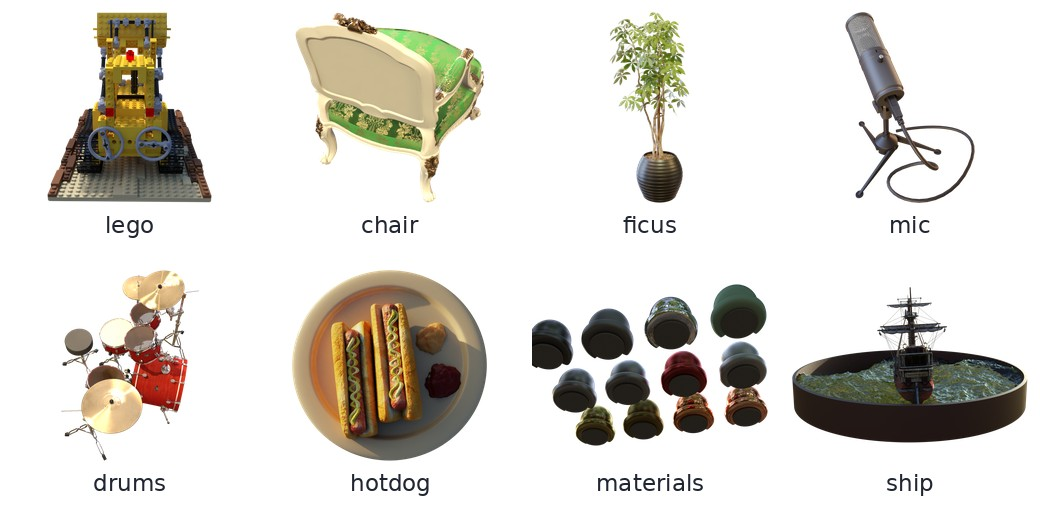

In [1]:
SCENES = ["lego", "chair", "ficus"]
iterations = 7000            # Kerbl iterations (same as baseline run)
resolution_divisor = 2       # 400x400

# factorized model (memory ~ num_primitives * rays_per_batch * num_samples; ~4 GB here)
PROPOSED = dict(
    iterations=1000,         # steps of 256 rays each (a Kerbl iteration = 1 full image)
    num_primitives=512,      # time scales with this; 1024 = ~2x slower
    rays_per_batch=256,      # lower if out of memory
    num_samples=64,          # samples per ray
    d_qk=16, hidden_dim=16, num_features=32,
    attention_mode="exact",  # or "performer"
    lr_geom=1e-3, lr_app=1e-2, lr_mlp=1e-3, lr_final_ratio=0.1,
    eval_chunk=1024,         # auto-halves if out of memory
    test_stride=50,          # score 4 of the 200 test views (1 = all 200)
    seed=0, log_every=100,
)

available = ("lego", "chair", "ficus", "mic", "drums", "hotdog", "materials", "ship")
if not SCENES or len(set(SCENES)) != len(SCENES) or any(name not in available for name in SCENES):
    raise ValueError(f"Choose one or more distinct scene names from {available}")
if iterations <= 0 or resolution_divisor not in (1, 2):
    raise ValueError("Use a positive iteration count and a resolution divisor of 1 or 2.")
print("Scenes to train in order:", ", ".join(SCENES))

from pathlib import Path
import os
import sys
import json
import subprocess
import tempfile
import time
import hashlib
from collections import deque

root = Path("/content/kerbl_project3")
root.mkdir(parents=True, exist_ok=True)
ref = "414b553ef1d3032ea634b7b7a1d121173f36592c"
data_revision = "ba2938ee53ed123b179e1fc1b1adad58ae83c97e"
repo = root / ("reference_" + ref[:8])

def run(*args, **kwargs):
    args = [str(x) for x in args]
    if kwargs.get("capture_output") or "stdout" in kwargs:
        return subprocess.run(args, check=True, **kwargs)
    # Forward child-process output to the notebook so Colab saves compiler diagnostics.
    with subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, errors="replace", bufsize=1, **kwargs) as process:
        recent = deque(maxlen=18)
        for line in process.stdout:
            print(line, end="", flush=True)
            recent.append(line)
        status = process.wait()
    if status:
        raise RuntimeError(f"{Path(args[0]).name} exited with status {status}.\n" + "".join(recent))
    return subprocess.CompletedProcess(args, status)

try:
    gpu = run("nvidia-smi", "--query-gpu=name", "--format=csv,noheader", capture_output=True, text=True).stdout.strip()
except (FileNotFoundError, subprocess.CalledProcessError):
    raise RuntimeError("No NVIDIA GPU. Runtime > Change runtime type > A100, L4 or T4 GPU.")
print("GPU:", gpu)
if not (repo / ".git").exists():
    run("git", "clone", "https://github.com/graphdeco-inria/gaussian-splatting.git", repo)
    run("git", "-C", repo, "checkout", "--detach", ref)
head = run("git", "-C", repo, "rev-parse", "HEAD", capture_output=True, text=True).stdout.strip()
assert head == ref, "Use the pinned public checkout for this baseline."
run("git", "-C", repo, "submodule", "update", "--init", "--recursive", "--", "submodules")
run("git", "-C", repo, "diff", "--exit-code", "--ignore-submodules=untracked", "HEAD")
print("Baseline commit:", head)

Scenes to train in order: lego, chair, ficus
GPU: NVIDIA L4
Cloning into '/content/kerbl_project3/reference_414b553e'...
HEAD is now at 414b553 Merge pull request #203 from Khoa-NT/patch-1
Submodule 'submodules/diff-gaussian-rasterization' (https://github.com/graphdeco-inria/diff-gaussian-rasterization) registered for path 'submodules/diff-gaussian-rasterization'
Submodule 'submodules/simple-knn' (https://gitlab.inria.fr/bkerbl/simple-knn.git) registered for path 'submodules/simple-knn'
Cloning into '/content/kerbl_project3/reference_414b553e/submodules/diff-gaussian-rasterization'...
Cloning into '/content/kerbl_project3/reference_414b553e/submodules/simple-knn'...
Submodule path 'submodules/diff-gaussian-rasterization': checked out '59f5f77e3ddbac3ed9db93ec2cfe99ed6c5d121d'
Submodule 'third_party/glm' (https://github.com/g-truc/glm.git) registered for path 'submodules/diff-gaussian-rasterization/third_party/glm'
Cloning into '/content/kerbl_project3/reference_414b553e/submodules/diff

### Install the reference code once

This cell installs or repairs the CUDA 11.8 environment, then checks both GPU extensions on a small input. When it succeeds, you will see **Reference implementation ready.** Build output appears below the cell while it runs.

In [2]:
from urllib.request import urlretrieve
import tarfile
import shutil

mamba = root / "micromamba"
prefix = root / "env-cu118"
if not mamba.exists():
    archive = root / "micromamba.tar.bz2"
    urlretrieve("https://micro.mamba.pm/api/micromamba/linux-64/2.10.0", archive)
    with tarfile.open(archive) as bundle, mamba.open("wb") as out:
        shutil.copyfileobj(bundle.extractfile("bin/micromamba"), out)
    mamba.chmod(0o755)

base_env = {**os.environ, "MAMBA_ROOT_PREFIX": str(root / "mamba-cache")}
# Install the matching runtime explicitly. The CUDA headers alone accept newer,
# incompatible CUDA runtimes and can leave lib/libcudart.so pointing to a missing file.
runtime_link = prefix / "lib/libcudart.so"
runtime_ok = runtime_link.is_file() and runtime_link.resolve().name == "libcudart.so.11.8.89"
packages = ["python=3.10", "pip", "setuptools<71", "wheel=0.44", "ninja", "gxx_linux-64=11",
            "sysroot_linux-64=2.17", "cuda-nvcc=11.8.89", "cuda-cudart=11.8.89",
            "cuda-cudart-dev=11.8.89", "cuda-cccl=11.8.89"]
if not runtime_ok or not list((prefix / "conda-meta").glob("wheel-0.44.*.json")):
    action = "install" if (prefix / "conda-meta/history").exists() else "create"
    run(mamba, action, "-y", "-p", prefix, "--override-channels", "--no-channel-priority",
        "-c", "nvidia/label/cuda-11.8.0", "-c", "conda-forge", *packages, env=base_env)
if not runtime_link.is_file() or runtime_link.resolve().name != "libcudart.so.11.8.89":
    raise RuntimeError(f"Expected the CUDA 11.8 runtime at {runtime_link}.")
print("CUDA runtime:", runtime_link.resolve(), flush=True)

build_env = {**base_env, "CUDA_HOME": str(prefix), "MAX_JOBS": "1", "PIP_PROGRESS_BAR": "off",
             "CC": str(prefix / "bin/x86_64-conda-linux-gnu-cc"),
             "CXX": str(prefix / "bin/x86_64-conda-linux-gnu-c++"),
             "PATH": str(prefix / "bin") + ":" + os.environ["PATH"],
             "LD_LIBRARY_PATH": str(prefix / "lib") + ":" + os.environ.get("LD_LIBRARY_PATH", ""),
             "NVCC_PREPEND_FLAGS": "--pre-include=cfloat"}
build_env.pop("PYTHONPATH", None)
# compile for the GPU we got (CUDA 11.8 supports up to A100 / L4)
ARCH = {"T4": "7.5", "V100": "7.0", "A100": "8.0", "L4": "8.9"}
arch = next((v for k, v in ARCH.items() if k in gpu), None)
if arch is None:
    raise RuntimeError(f"{gpu} isn't supported by the CUDA 11.8 build. Use A100, L4 or T4.")
build_env["TORCH_CUDA_ARCH_LIST"] = arch
py = prefix / "bin/python"

def baseline_python(*args, **kwargs):
    return run(py, *args, cwd=repo, env=build_env, **kwargs)

ready = prefix / "kerbl-cu118-extensions-verified-v2"
if not ready.exists():
    baseline_python("-m", "pip", "install", "numpy==1.26.4", "plyfile==1.1", "tqdm", "Pillow==10.4.0")
    baseline_python("-m", "pip", "install", "--index-url", "https://download.pytorch.org/whl/cu118",
                    "torch==2.2.2", "torchvision==0.17.2")
    baseline_python("-c", "import torch; assert torch.cuda.is_available(), 'Select a GPU runtime in Colab'; "
                    "print('Building for', torch.cuda.get_device_name(), 'with PyTorch', torch.__version__)")
    for extension in ("simple-knn", "diff-gaussian-rasterization"):
        print(f"Building {extension} ...", flush=True)
        baseline_python("-m", "pip", "install", "-v", "--no-build-isolation", "--no-deps",
                        f"./submodules/{extension}")

# Run one small kernel from each extension before downloading a scene.
smoke_check = """import torch
from simple_knn._C import distCUDA2
from diff_gaussian_rasterization import _C
points = torch.rand(1024, 3, device="cuda")
eye = torch.eye(4, device="cuda")
assert distCUDA2(points).shape == (len(points),)
assert _C.mark_visible(points, eye, eye).shape == (len(points),)
torch.cuda.synchronize()
print("Both CUDA extensions passed on", torch.cuda.get_device_name())
"""
baseline_python("-c", smoke_check)
baseline_python("train.py", "--help", stdout=subprocess.DEVNULL)
ready.touch()
print("Reference implementation ready.")

⚠ Shard Index for nvidia/label/cuda-11.8.0/linux-64 not available, falling back to flat repodata
Using Flat Repodata for nvidia/label/cuda-11.8.0/linux-64                                       ✔ Starting
Using Flat Repodata for nvidia/label/cuda-11.8.0/linux-64                                 ✔ Done (0.0 sec)
⚠ Shard Index for nvidia/label/cuda-11.8.0/noarch not available, falling back to flat repodata
Using Flat Repodata for nvidia/label/cuda-11.8.0/noarch                                         ✔ Starting
Using Flat Repodata for nvidia/label/cuda-11.8.0/noarch                                   ✔ Done (0.0 sec)
Fetch Shard Index for conda-forge/linux-64                                                      ⧖ Starting
Fetch Shard Index for conda-forge/linux-64                                                ✔ Done (0.1 sec)
Fetch Shard Index for conda-forge/noarch                                                        ⧖ Starting
Fetch Shard Index for conda-forge/noarch                   

### Load the images and train a model for each scene

These functions are called by the final cell. Each scene uses 100 training views and 200 held-out test views, a white background and the selected resolution. At divisor 2 the images are 400 × 400.

In [3]:
from PIL import Image
from IPython.display import display
try:
    from huggingface_hub import snapshot_download
except ImportError:
    run(sys.executable, "-m", "pip", "install", "huggingface_hub")
    from huggingface_hub import snapshot_download



def prepare_scene(scene_name):
    data_root = root / ("data_" + data_revision[:8])
    scene = data_root / scene_name
    snapshot_download("rishitdagli/nerf-gs-datasets", repo_type="dataset", revision=data_revision,
                      local_dir=str(data_root), max_workers=4,
                      allow_patterns=[f"{scene_name}/transforms_train.json", f"{scene_name}/transforms_test.json",
                                      f"{scene_name}/train/*.png", f"{scene_name}/test/*.png"],
                      ignore_patterns=["*depth*.png", "*normal*.png"])
    splits = {}
    for split in ("train", "test"):
        frames = json.loads((scene / f"transforms_{split}.json").read_text())["frames"]
        splits[split] = [str(Path(frame["file_path"]).with_suffix(".png")) for frame in frames]
        for image_name in splits[split]:
            if not (scene / image_name).is_file():
                raise FileNotFoundError(scene / image_name)
        print(split, len(frames), "views")
    assert len(splits["train"]) == 100 and len(splits["test"]) == 200
    with Image.open(scene / splits["train"][0]) as im:
        print("Input image dimensions:", im.size)
        display(im.resize((320, 320)))
    return scene, splits

In [4]:
profile_training = r'''import json
import runpy
import sys
from pathlib import Path
import torch

destination = Path(sys.argv[1])
sys.argv = sys.argv[2:]
sys.path.insert(0, str(Path(sys.argv[0]).resolve().parent))
torch.cuda.reset_peak_memory_stats()
runpy.run_path(sys.argv[0], run_name="__main__")
torch.cuda.synchronize()
peak_mib = torch.cuda.max_memory_allocated() / 2**20
destination.write_text(json.dumps({"peak_train_torch_allocated_MiB": peak_mib}))
'''

def train_scene(scene_name, scene):
    model = Path(tempfile.mkdtemp(prefix=f"{scene_name}_{iterations}_", dir=root))
    command = ["train.py", "-s", str(scene), "-m", str(model), "--eval", "-w",
               "-r", str(resolution_divisor), "--iterations", str(iterations),
               "--data_device", "cpu", "--test_iterations", "-1", "--save_iterations", str(iterations)]
    profile_path = model / "training_memory.json"
    start = time.perf_counter()
    baseline_python("-c", profile_training, profile_path, *command)
    train_minutes = (time.perf_counter() - start) / 60
    cloud = model / "point_cloud" / f"iteration_{iterations}" / "point_cloud.ply"
    assert cloud.is_file(), "The final Gaussian cloud is missing."
    print(f"Training took {train_minutes:.2f} minutes. Model folder: {model}")
    return model, cloud, train_minutes, command

### Render, score and save the comparison

Each scene produces three pairs of images with an original and a model render. Metrics use all 200 test views. Each summary records the final splat and parameter counts, model size, wall-clock training time, peak PyTorch GPU tensor memory, rendering speed, PSNR, SSIM, L1 and VGG-LPIPS.

In [5]:
def render_scene(scene_name, model, splits):
    import matplotlib.pyplot as plt

    baseline_python("render.py", "-m", model, "--iteration", str(iterations), "--skip_train")
    view_dir = model / "test" / f"ours_{iterations}"
    rendered = sorted((view_dir / "renders").glob("*.png"))
    expected_files = [f"{i:05d}.png" for i in range(len(splits["test"]))]
    assert [f.name for f in rendered] == expected_files, "Incomplete held-out renders."
    report = model / "baseline_results"
    report.mkdir(exist_ok=True)
    examples = [0, len(rendered) // 2, len(rendered) - 1]
    fig, axes = plt.subplots(3, 2, figsize=(7, 9))
    for row, idx in enumerate(examples):
        for col, (folder, label) in enumerate([("gt", "Original"), ("renders", "Kerbl baseline")]):
            with Image.open(view_dir / folder / rendered[idx].name) as im:
                axes[row, col].imshow(im)
            axes[row, col].set_title(f"{label} · {splits['test'][idx]}")
            axes[row, col].axis("off")
    fig.tight_layout()
    fig.savefig(report / "example_views.png", dpi=150)
    plt.suptitle(scene_name, y=1.01)
    plt.show()
    plt.close(fig)
    return view_dir, report

In [6]:
score_code = r'''import csv, json, sys
from pathlib import Path
from PIL import Image
import torch
from torchvision.transforms.functional import to_tensor
from utils.image_utils import psnr
from utils.loss_utils import ssim, l1_loss
from lpipsPyTorch.modules.lpips import LPIPS

views, report = map(Path, sys.argv[1:3])
lpips = LPIPS(net_type="vgg").cuda().eval()
names = sorted((views / "renders").glob("*.png"))
if not names:
    raise ValueError("No rendered test views found.")
rows = []
with torch.inference_mode():
    for image in names:
        with Image.open(image) as pred, Image.open(views / "gt" / image.name) as ref:
            a = to_tensor(pred.convert("RGB")).unsqueeze(0).cuda()
            b = to_tensor(ref.convert("RGB")).unsqueeze(0).cuda()
        if a.shape != b.shape:
            raise ValueError(f"Image size mismatch for {image.name}")
        rows.append(dict(image=image.name, PSNR_dB=psnr(a, b).item(),
                         SSIM=ssim(a, b).item(), L1=l1_loss(a, b).item(), LPIPS_VGG=lpips(a, b).item()))
with (report / "per_view.csv").open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=rows[0])
    writer.writeheader()
    writer.writerows(rows)
means = {name: sum(row[name] for row in rows) / len(rows) for name in ("PSNR_dB", "SSIM", "L1", "LPIPS_VGG")}
(report / "quality.json").write_text(json.dumps(means, indent=2))
print(means)'''

timing_code = r'''import json, sys, time
from pathlib import Path
from argparse import ArgumentParser
import torch
from arguments import ModelParams, PipelineParams
from gaussian_renderer import render
from scene import Scene, GaussianModel
from utils.general_utils import safe_state
from plyfile import PlyData

model, checkpoint, cloud, report, source, divisor = sys.argv[1:]
safe_state(True)
parser = ArgumentParser()
model_params = ModelParams(parser)
pipe_params = PipelineParams(parser)
args = parser.parse_args(["-m", model, "-s", source, "--eval", "-w", "-r", divisor, "--data_device", "cpu"])
dataset = model_params.extract(args)
pipe = pipe_params.extract(args)
with torch.inference_mode():
    gaussians = GaussianModel(dataset.sh_degree)
    scene = Scene(dataset, gaussians, load_iteration=int(checkpoint), shuffle=False)
    cameras = scene.getTestCameras()
    bg = torch.ones(3, device="cuda") if dataset.white_background else torch.zeros(3, device="cuda")
    for camera in cameras[:10]:
        render(camera, gaussians, pipe, bg)
    torch.cuda.synchronize()
    start = time.perf_counter()
    for camera in cameras:
        render(camera, gaussians, pipe, bg)
    torch.cuda.synchronize()
    seconds = time.perf_counter() - start
vertex = PlyData.read(cloud)["vertex"]
parameters = (gaussians._xyz, gaussians._scaling, gaussians._rotation, gaussians._opacity,
              gaussians._features_dc, gaussians._features_rest)
assert all(t.shape[0] == vertex.count for t in parameters)
parameter_count = sum(t.numel() for t in parameters)
stats = dict(final_gaussians=vertex.count, trainable_parameters=parameter_count, model_MiB=Path(cloud).stat().st_size / 2**20,
             test_views=len(cameras), width=cameras[0].image_width, height=cameras[0].image_height,
             render_fps=len(cameras) / seconds, gpu=torch.cuda.get_device_name(0),
             torch=str(torch.__version__), cuda=torch.version.cuda)
(Path(report) / "efficiency.json").write_text(json.dumps(stats, indent=2))'''

def evaluate_scene(scene, model, cloud, view_dir, report):
    baseline_python("-c", score_code, view_dir, report)
    baseline_python("-c", timing_code, model, str(iterations), cloud, report, scene, resolution_divisor)

In [7]:
import csv
import zipfile
import pandas as pd
from google.colab import files



def save_scene_results(scene_name, scene, splits, model, report, train_minutes, command):
    quality = json.loads((report / "quality.json").read_text())
    efficiency = json.loads((report / "efficiency.json").read_text())
    memory_record = model / "training_memory.json"
    memory = json.loads(memory_record.read_text()) if memory_record.exists() else {"peak_train_torch_allocated_MiB": None}
    row = dict(scene=scene_name, method="Kerbl 3DGS", iterations=iterations, train_views=len(splits["train"]),
               train_minutes=train_minutes, **efficiency, **memory, **quality)
    display(pd.DataFrame([row]).round(4))
    with (report / "summary.csv").open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=row)
        writer.writeheader()
        writer.writerow(row)
    metadata = dict(repo="graphdeco-inria/gaussian-splatting", commit=ref, seed=0,
                    dataset="rishitdagli/nerf-gs-datasets", dataset_revision=data_revision,
                    resolution_divisor=resolution_divisor, white_background=True,
                    test_order=splits["test"], train_order=splits["train"], train_command=command,
                    input_cloud_sha256=hashlib.sha256((model / "input.ply").read_bytes()).hexdigest(),
                    submodules=run("git", "-C", repo, "submodule", "status", "--recursive", "--", "submodules",
                                   capture_output=True, text=True).stdout.splitlines(),
                    memory_definition="Peak PyTorch-allocated GPU tensor memory during train.py, including scene setup, in MiB.",
                    trainable_parameters_definition="Scalar elements of the six learned Gaussian tensors in the saved model.",
                    render_timing="10 warm-up views, all test cameras once, CUDA sync before/after; excludes disk I/O")
    (report / "settings.json").write_text(json.dumps(metadata, indent=2))
    (report / "score_views.py").write_text(score_code + "\n")
    (report / "time_baseline.py").write_text(timing_code + "\n")
    if memory_record.exists():
        (report / "profile_training.py").write_text(profile_training + "\n")
    (report / "README.txt").write_text(
        "Use summary.csv for the baseline row and per_view.csv for individual image scores.\n"
        "settings.json maps render indices to original test-camera paths in order.\n"
        "To score proposal images, use identical ground-truth targets. Inside the baseline Python environment, "
        "copy score_views.py into the clean reference repo and run "
        "python score_views.py VIEW_FOLDER EXISTING_OUTPUT_FOLDER from that repo. "
        "VIEW_FOLDER should contain renders/ and gt/ with matching PNG names.\n"
        "For matching memory measurements, run the included profile_training.py from the model repo root with "
        "python /path/to/profile_training.py training_memory.json train.py YOUR_TRAINING_ARGUMENTS "
        "from the same working directory used for a normal training run. Peak memory is PyTorch tensor allocation.\n"
    )
    bundle = model / f"{scene_name}_kerbl_{iterations}_results.zip"
    with zipfile.ZipFile(bundle, "w", compression=zipfile.ZIP_DEFLATED) as out:
        for entry in sorted(report.iterdir()):
            out.write(entry, entry.name)
        out.write(model / "input.ply", "initial_cloud.ply")
        for split in ("train", "test"):
            out.write(scene / f"transforms_{split}.json", f"transforms_{split}.json")

    return bundle

### Factorized model

Writes our model files (`factorized_gaussian.py`, `attention.py`, `factorized_render.py`) and the training script. Uses Kerbl's image loader and scoring so both models are evaluated on identical images.

In [8]:
proposed_files = {
 "scene/factorized_gaussian.py": "import torch\n"
    "import torch.nn as nn\n"
    "from scene.attention import Attention\n"
    "\n"
    "\n"
    "class FactorizedGaussianModel(nn.Module):\n"
    "    \"\"\"\n"
    "    Replaces 3D ellipsoids with N factorized primitives:\n"
    "    p(x, y, z) = p_2D(x, y) * p_z(z | x, y)\n"
    "    \"\"\"\n"
    "    def __init__(\n"
    "        self,\n"
    "        num_primitives: int,\n"
    "        d_qk: int = 16,\n"
    "        hidden_dim: int = 16,\n"
    "        num_features: int = 32,\n"
    "        attention_mode: str = \"exact\",\n"
    "    ):\n"
    "        super().__init__()\n"
    "        self.num_primitives = num_primitives\n"
    "\n"
    "        # 1. 2D Gaussian parameters: mean mu_i in R^2, [log-scales (s_x, s_y), angle theta] for covariance matrix Sigma\n"
    "        self._xy = nn.Parameter(torch.empty(num_primitives, 2).uniform_(-1.0, 1.0))\n"
    "        self._scaling = nn.Parameter(torch.full((num_primitives, 2), -2.8))\n"
    "        self._theta = nn.Parameter(torch.zeros(num_primitives, 1))\n"
    "\n"
    "        # 2. Appearance parameters: opacity alpha_i and RGB color c_i\n"
    "        self._opacity = nn.Parameter(torch.full((num_primitives, 1), 0.0))\n"
    "        self._rgb = nn.Parameter(torch.zeros(num_primitives, 3))\n"
    "\n"
    "        # 3. Per-primitive attention module p_z(z | x, y)\n"
    "        self.depth_attention = Attention(\n"
    "            num_primitives=num_primitives,\n"
    "            d_qk=d_qk,\n"
    "            hidden_dim=hidden_dim,\n"
    "            num_features=num_features,\n"
    "            mode=attention_mode,\n"
    "        )\n"
    "\n"
    "    @property\n"
    "    def get_xy(self) -> torch.Tensor:\n"
    "        return self._xy\n"
    "\n"
    "    @property\n"
    "    def get_scaling(self) -> torch.Tensor:\n"
    "        return torch.exp(self._scaling) # ensures radius stays positive; Kerbl uses log logic in line 40 of gaussian_model.py\n"
    "\n"
    "    @property\n"
    "    def get_opacity(self) -> torch.Tensor:\n"
    "        return torch.sigmoid(self._opacity)\n"
    "\n"
    "    @property\n"
    "    def get_rgb(self) -> torch.Tensor:\n"
    "        return torch.sigmoid(self._rgb)\n"
    "\n"
    "    def evaluate_2d_gaussian(self, xy: torch.Tensor) -> torch.Tensor:\n"
    "        \"\"\"\n"
    "        Evaluate unnormalized 2D Gaussian\n"
    "        p_2D^i(x, y) = exp(-0.5 * (u - mu_i)^T Sigma_i^{-1} (u - mu_i))\n"
    "        xy: (B, 2) -> returns (N, B)\n"
    "        \"\"\"\n"
    "        diff = xy.unsqueeze(0) - self._xy.unsqueeze(1) # (u - mu_i) ; (N, B, 2)\n"
    "\n"
    "        # rotate into each primitive's local ellipse axes using R(theta)^T = R(-theta)\n"
    "        cos_t = torch.cos(self._theta)  # (N, 1)\n"
    "        sin_t = torch.sin(self._theta)  # (N, 1)\n"
    "\n"
    "        dx = diff[..., 0]  # x-offsets from (N, B, 2); (N, B)\n"
    "        dy = diff[..., 1]  # y-offsets from (N, B, 2); (N, B)\n"
    "\n"
    "        # local_coord = [[cos(theta), sin(theta)], [-sin(theta), cos(theta)]] x [dx, dy]\n"
    "        local_x = cos_t * dx + sin_t * dy\n"
    "        local_y = -sin_t * dx + cos_t * dy\n"
    "\n"
    "        scales = self.get_scaling + 1e-6  # (N, 2)\n"
    "        p2d_term = (local_x / scales[:, 0:1]) ** 2 + (local_y / scales[:, 1:2]) ** 2\n"
    "\n"
    "        return torch.exp(-0.5 * p2d_term)  # (N, B)\n"
    "\n"
    "    def forward(self, pts: torch.Tensor):\n"
    "        \"\"\"\n"
    "        Evaluates total density and weighted RGB color at ray sample points.\n"
    "        pts: (R, M, 3) world coordinates along R rays and M depth slices\n"
    "        returns:\n"
    "            sigma_total: (R, M, 1) total density at each (x, y, z_m)\n"
    "            color_weighted: (R, M, 3) density-weighted RGB C(x, y, z_m)\n"
    "        \"\"\"\n"
    "        R, M, _ = pts.shape\n"
    "        xy_flat = pts[..., :2].reshape(R * M, 2)\n"
    "\n"
    "        # 1. p_2D^i(x, y) -> shape (N, R, M)\n"
    "        p_2d = self.evaluate_2d_gaussian(xy_flat).reshape(self.num_primitives, R, M)\n"
    "\n"
    "        # 2. p_z^i(z_m | x, y) -> shape (N, R, M)\n"
    "        p_z = self.depth_attention(pts)\n"
    "\n"
    "        # 3. sigma_i(x, y, z_m) = alpha_i * p_2D^i * p_z^i -> (N, R, M)\n"
    "        alpha = self.get_opacity.unsqueeze(-1)  # (N, 1, 1)\n"
    "        sigma_i = alpha * M * p_2d * p_z\n"
    "\n"
    "        # 4. Sum over all N primitives at each depth slice -> (R, M, 1)\n"
    "        sigma_total = torch.sum(sigma_i, dim=0).unsqueeze(-1)\n"
    "\n"
    "        # 5. Weighted average color C(x, y, z_m) -> (R, M, 3)\n"
    "        rgb = self.get_rgb  # (N, 3)\n"
    "        color_weighted = torch.einsum(\"nrm,nc->rmc\", sigma_i, rgb) / (sigma_total + 1e-8)\n"
    "\n"
    "        return sigma_total, color_weighted\n"
    "    \n"
    "    def get_stats(self):\n"
    "        \"\"\"Returns counts of total splats, non-transparent (active) splats, and total parameters.\"\"\"\n"
    "        active_splats = int((self.get_opacity > 0.01).sum().item())\n"
    "        total_params = sum(p.numel() for p in self.parameters()) # e.g., (x, y), theta, w1, b1, etc. & number of elements inside trainable param tensors\n"
    "        return {\n"
    "            \"total_splats\": self._xy.shape[0], \n"
    "            \"active_splats\": active_splats, \n"
    "            \"total_params\": total_params\n"
    "        }",
 "scene/attention.py": "import math\n"
    "import torch\n"
    "import torch.nn as nn\n"
    "\n"
    "\n"
    "class BatchedMLP(nn.Module):\n"
    "    \"\"\"N independent lightweight MLPs evaluated in parallel\"\"\"\n"
    "    def __init__(self, num_primitives: int, in_dim: int, hidden_dim: int, out_dim: int):\n"
    "        super().__init__()\n"
    "        \n"
    "        self.w1 = nn.Parameter(torch.randn(num_primitives, in_dim, hidden_dim) * 0.1) # weights; shape: (N, in_dim, hiden_dim)\n"
    "        self.b1 = nn.Parameter(torch.zeros(num_primitives, 1, hidden_dim)) # biases\n"
    "        self.w2 = nn.Parameter(torch.randn(num_primitives, hidden_dim, out_dim) * 0.1) # weights; shape: (N, hiden_dim, out_dim)\n"
    "        self.b2 = nn.Parameter(torch.zeros(num_primitives, 1, out_dim)) # biases\n"
    "\n"
    "    def forward(self, x: torch.Tensor) -> torch.Tensor:\n"
    "        \"\"\"\n"
    "        x: (B, in_dim) where B is total queried coordinates (e.g., R * M)\n"
    "        returns: (N, B, out_dim)\n"
    "        \"\"\"\n"
    "        h = torch.einsum(\"bi,nih->nbh\", x, self.w1) + self.b1 # (B, in_dim) x (N, in_dim, hidden_dim) -> (N, B, hidden_dim)\n"
    "        h = torch.tanh(h)\n"
    "        out = torch.einsum(\"nbh,nho->nbo\", h, self.w2) + self.b2 # (N, B, hidden_dim) x (N, hidden_dim, out_dim) -> (N, B, out_dim)\n"
    "        return out\n"
    "\n"
    "\n"
    "class Attention(nn.Module):\n"
    "    \"\"\"\n"
    "    Computes p_z(z_m | x, y) for N primitives across R rays and M depth slices.\n"
    "    \"\"\"\n"
    "    def __init__(\n"
    "        self,\n"
    "        num_primitives: int,\n"
    "        d_qk: int = 16,\n"
    "        hidden_dim: int = 16,\n"
    "        num_features: int = 32,\n"
    "        mode: str = \"exact\",\n"
    "    ):\n"
    "        super().__init__()\n"
    "        assert mode in (\"exact\", \"performer\")\n"
    "        self.num_primitives = num_primitives\n"
    "        self.d_qk = d_qk\n"
    "        self.num_features = num_features\n"
    "        self.mode = mode\n"
    "\n"
    "        self.q_net = BatchedMLP(num_primitives, in_dim=2, hidden_dim=hidden_dim, out_dim=d_qk) # q_i(x, y): R^2 -> R^{d_QK}\n"
    "        self.k_net = BatchedMLP(num_primitives, in_dim=1, hidden_dim=hidden_dim, out_dim=d_qk) # k_i(z): R -> R^{d_QK}\n"
    "\n"
    "        omega = self._create_projection_matrix(num_features, d_qk) # fixed projection matrix omega in R^{r x d_QK} for performer\n"
    "        self.register_buffer(\"omega\", omega)\n"
    "\n"
    "    @staticmethod\n"
    "    def _create_projection_matrix(r: int, d: int) -> torch.Tensor:\n"
    "        \"\"\"Draws orthogonal rows to create projection matrix (Choromanski et al., Section 2.4/Appendix B.2).\"\"\"\n"
    "        blocks = []\n"
    "        for _ in range(math.ceil(r / d)):\n"
    "            q, _ = torch.linalg.qr(torch.randn(d, d)) # generates d x d orthogonal matrix\n"
    "            norms = torch.linalg.norm(torch.randn(d, d), dim=1, keepdim=True)\n"
    "            blocks.append(q * norms)\n"
    "        return torch.cat(blocks, dim=0)[:r]  # (r, d)\n"
    "\n"
    "    def _favor_plus_features(self, v: torch.Tensor) -> torch.Tensor:\n"
    "        \"\"\"\n"
    "        Feature map:\n"
    "        phi(v) = exp(-||v||^2 / 2) / sqrt(r) * exp(Omega @ v)\n"
    "        v: (N, B, d_qk) -> returns (N, B, r)\n"
    "        \"\"\"\n"
    "        norm_sq = torch.sum(v ** 2, dim=-1, keepdim=True)  # (N, B, 1)\n"
    "        proj = torch.einsum(\"rd,nbd->nbr\", self.omega, v)  # (N, B, r)\n"
    "        proj = torch.clamp(proj, max=20.0) # clamp to prevent overflow\n"
    "        return torch.exp(proj - 0.5 * norm_sq) / math.sqrt(self.num_features)\n"
    "\n"
    "    def forward(self, pts: torch.Tensor) -> torch.Tensor:\n"
    "        \"\"\"\n"
    "        pts: (R, M, 3) world coordinates (x, y, z_m) along R rays and M depth slices\n"
    "        returns p_z: (N, R, M) normalized depth attention weights summing to 1 over M\n"
    "        \"\"\"\n"
    "        R, M, _ = pts.shape\n"
    "        B = R * M\n"
    "        flat_pts = pts.reshape(B, 3)\n"
    "\n"
    "        xy = flat_pts[:, :2]  # (B, 2)\n"
    "        z = flat_pts[:, 2:3]  # (B, 1)\n"
    "\n"
    "        # Evaluate q_i(x, y) and k_i(z) for all N primitives: shape (N, R, M, d_qk)\n"
    "        q = self.q_net(xy).reshape(self.num_primitives, R, M, self.d_qk)\n"
    "        k = self.k_net(z).reshape(self.num_primitives, R, M, self.d_qk)\n"
    "\n"
    "        if self.mode == \"exact\":\n"
    "            # Dot product q(x,y)^T k(z_m) at each sample, softmax over M\n"
    "            logits = torch.sum(q * k, dim=-1)  # (N, R, M)\n"
    "            p_z = torch.softmax(logits, dim=-1)\n"
    "        else:\n"
    "            # Performer positive random features\n"
    "            phi_q = self._favor_plus_features(q.reshape(self.num_primitives, B, self.d_qk))\n"
    "            phi_k = self._favor_plus_features(k.reshape(self.num_primitives, B, self.d_qk))\n"
    "\n"
    "            phi_q = phi_q.reshape(self.num_primitives, R, M, self.num_features)\n"
    "            phi_k = phi_k.reshape(self.num_primitives, R, M, self.num_features)\n"
    "\n"
    "            # Numerator: phi(q)^T phi(k_m) -> (N, R, M)\n"
    "            numer = torch.sum(phi_q * phi_k, dim=-1)\n"
    "\n"
    "            # Denominator: phi(q)^T * sum_j phi(k_j) -> (N, R, M)\n"
    "            s_i = torch.sum(phi_k, dim=2, keepdim=True)  # (N, R, 1, r)\n"
    "            denom = torch.sum(phi_q * s_i, dim=-1) + 1e-8  # (N, R, M)\n"
    "            p_z = numer / denom\n"
    "\n"
    "        return p_z",
 "gaussian_renderer/factorized_render.py": "import math\n"
    "import torch\n"
    "\n"
    "def get_rays_from_camera(viewpoint_camera, device=\"cuda\"):\n"
    "    \"\"\"\n"
    "    Generates world-space ray origins and unit directions for every pixel\n"
    "    in Kerbl's Camera object.\n"
    "    returns:\n"
    "        rays_o: (H * W, 3) camera center in world coordinates\n"
    "        rays_d: (H * W, 3) unit ray direction per pixel in world coordinates\n"
    "    \"\"\"\n"
    "    H = viewpoint_camera.image_height\n"
    "    W = viewpoint_camera.image_width\n"
    "\n"
    "    # Focal lengths in pixels from field of view\n"
    "    fx = W / (2.0 * math.tan(viewpoint_camera.FoVx * 0.5))\n"
    "    fy = H / (2.0 * math.tan(viewpoint_camera.FoVy * 0.5))\n"
    "\n"
    "    # Pixel grid (u, v)\n"
    "    v, u = torch.meshgrid(\n"
    "        torch.arange(H, dtype=torch.float32, device=device),\n"
    "        torch.arange(W, dtype=torch.float32, device=device),\n"
    "        indexing=\"ij\",\n"
    "    )\n"
    "\n"
    "    # Camera-space ray directions (same convention used by 3DGS: +x right, +y down, +z forward)\n"
    "    dirs_cam = torch.stack(\n"
    "        [(u - W * 0.5) / fx, (v - H * 0.5) / fy, torch.ones_like(u)], # centers pixel coordinates around (0, 0) and converts to real-world coordinates\n"
    "        dim=-1,\n"
    "    )  # (H, W, 3)\n"
    "\n"
    "    # Rotate directions into world space using camera-to-world rotation\n"
    "    c2w_rot = viewpoint_camera.world_view_transform[:3, :3].to(device)\n"
    "    rays_d = dirs_cam @ c2w_rot.T  # (H, W, 3)\n"
    "    rays_d = rays_d / torch.norm(rays_d, dim=-1, keepdim=True)\n"
    "\n"
    "    rays_o = viewpoint_camera.camera_center.to(device).expand_as(rays_d)\n"
    "    return rays_o.reshape(-1, 3), rays_d.reshape(-1, 3)\n"
    "\n"
    "def volume_render_rays(\n"
    "    model,\n"
    "    rays_o: torch.Tensor,\n"
    "    rays_d: torch.Tensor,\n"
    "    near: float = 2.0, # uses tighter set (near, far) than Kerbl as starting point\n"
    "    far: float = 6.0,\n"
    "    num_samples: int = 64,\n"
    "    white_background: bool = True,\n"
    "):\n"
    "    \"\"\"\n"
    "    Renders RGB colors for a batch of R rays by marching M depth slices\n"
    "    and applying front-to-back alpha compositing.\n"
    "    rays_o, rays_d: (R, 3)\n"
    "    returns:\n"
    "        rgb_map: (R, 3) predicted pixel colors\n"
    "    \"\"\"\n"
    "    R = rays_o.shape[0]\n"
    "    device = rays_o.device\n"
    "\n"
    "    # 1. Sample M depth steps t_1, ..., t_M between near and far planes\n"
    "    t_vals = torch.linspace(near, far, num_samples, device=device)  # (M,)\n"
    "    delta_z = (far - near) / num_samples\n"
    "\n"
    "    if model.training:\n"
    "        t_vals = t_vals + (torch.rand(R, num_samples, device=device) - 0.5) * delta_z # adding small jitter to prevent overfitting\n"
    "    else:\n"
    "        t_vals = t_vals.unsqueeze(0).expand(R, num_samples)\n"
    "\n"
    "    # 2. Compute 3D world coordinates pts = o + t * d -> shape (R, M, 3)\n"
    "    pts = rays_o.unsqueeze(1) + rays_d.unsqueeze(1) * t_vals.unsqueeze(-1)\n"
    "\n"
    "    # 3. Query FactorizedGaussianModel -> sigma_total (R, M, 1), color_weighted (R, M, 3)\n"
    "    sigma_total, color_weighted = model(pts)\n"
    "    sigma = sigma_total.squeeze(-1)  # (R, M)\n"
    "\n"
    "    # 4. Front-to-back volume rendering\n"
    "    alpha = 1.0 - torch.exp(-sigma * delta_z)  # (R, M)\n"
    "\n"
    "    ones = torch.ones((R, 1), device=device)\n"
    "    transmittance = torch.cumprod(torch.cat([ones, 1.0 - alpha + 1e-10], dim=-1), dim=-1)[:, :-1]  # (R, M)\n"
    "\n"
    "    weights = transmittance * alpha  # (R, M)\n"
    "    rgb_map = torch.sum(weights.unsqueeze(-1) * color_weighted, dim=1)  # (R, 3)\n"
    "\n"
    "    if white_background:\n"
    "        acc_alpha = torch.sum(weights, dim=-1, keepdim=True)  # (R, 1)\n"
    "        rgb_map = rgb_map + (1.0 - acc_alpha)\n"
    "\n"
    "    return rgb_map\n"
    "\n"
    "def render_factorized(\n"
    "    viewpoint_camera,\n"
    "    pc,\n"
    "    bg_color: torch.Tensor,\n"
    "    num_samples: int = 64,\n"
    "    ray_indices: torch.Tensor = None,\n"
    "    chunk_size: int = 256,\n"
    "):\n"
    "    \"\"\"\n"
    "    Factorized-Gaussian replacement for Kerbl's render() function.\n"
    "    - If ray_indices is provided (training): renders only that random subset of rays.\n"
    "    - If ray_indices is None (evaluation): renders the full image in VRAM-safe chunks.\n"
    "    \"\"\"\n"
    "    device = pc._xy.device\n"
    "    H, W = viewpoint_camera.image_height, viewpoint_camera.image_width\n"
    "    white_bg = bool(bg_color.sum().item() > 1.5)\n"
    "\n"
    "    rays_o, rays_d = get_rays_from_camera(viewpoint_camera, device=device)\n"
    "\n"
    "    if ray_indices is not None: # training\n"
    "        rgb = volume_render_rays(\n"
    "            pc,\n"
    "            rays_o[ray_indices],\n"
    "            rays_d[ray_indices],\n"
    "            num_samples=num_samples,\n"
    "            white_background=white_bg,\n"
    "        )\n"
    "        return {\"render\": rgb}\n"
    "\n"
    "    rgb_chunks = []\n"
    "    for start in range(0, H * W, chunk_size): # evaluation\n"
    "        end = min(start + chunk_size, H * W)\n"
    "        chunk_rgb = volume_render_rays(\n"
    "            pc,\n"
    "            rays_o[start:end],\n"
    "            rays_d[start:end],\n"
    "            num_samples=num_samples,\n"
    "            white_background=white_bg,\n"
    "        )\n"
    "        rgb_chunks.append(chunk_rgb)\n"
    "\n"
    "    full_img = torch.cat(rgb_chunks, dim=0).reshape(H, W, 3).permute(2, 0, 1)  # (3, H, W)\n"
    "    return {\"render\": full_img}"
}

proposed_code = r'''import json, sys, time
from argparse import Namespace
from pathlib import Path

import numpy as np
import torch
import torchvision

cfg = json.loads(sys.argv[1])
ref_repo, team_dir = Path(cfg["ref_repo"]), Path(cfg["team_dir"])
sys.path.insert(0, str(ref_repo))

# use Kerbl's loader so both models get the same images/cameras
import scene as ref_scene
import gaussian_renderer as ref_renderer
from scene.dataset_readers import readCamerasFromTransforms
from utils.camera_utils import cameraList_from_camInfos

# add our factorized files (kept in a separate folder)
ref_scene.__path__.append(str(team_dir / "scene"))
ref_renderer.__path__.append(str(team_dir / "gaussian_renderer"))
from scene.factorized_gaussian import FactorizedGaussianModel
from gaussian_renderer.factorized_render import get_rays_from_camera, volume_render_rays, render_factorized

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = True  # faster matmuls on A100/L4 (no effect on T4)
torch.manual_seed(cfg["seed"]); np.random.seed(cfg["seed"])
if dev == "cuda":
    torch.cuda.reset_peak_memory_stats()

# data
args = Namespace(resolution=cfg["resolution_divisor"], data_device="cpu")
src = cfg["scene"]
train_cams = cameraList_from_camInfos(readCamerasFromTransforms(src, "transforms_train.json", True), 1.0, args)
test_cams = cameraList_from_camInfos(readCamerasFromTransforms(src, "transforms_test.json", True), 1.0, args)
print(f"{len(train_cams)} train / {len(test_cams)} test views at "
      f"{train_cams[0].image_width}x{train_cams[0].image_height}", flush=True)

# precompute all training rays
rays_o, rays_d, rgbs = [], [], []
for cam in train_cams:
    o, d = get_rays_from_camera(cam, device=dev)
    rays_o.append(o); rays_d.append(d)
    rgbs.append(cam.original_image.to(dev).reshape(3, -1).T)
rays_o, rays_d, rgbs = torch.cat(rays_o), torch.cat(rays_d), torch.cat(rgbs)

# model
model = FactorizedGaussianModel(num_primitives=cfg["num_primitives"], d_qk=cfg["d_qk"],
                                hidden_dim=cfg["hidden_dim"], num_features=cfg["num_features"],
                                attention_mode=cfg["attention_mode"]).to(dev)
opt = torch.optim.Adam([
    {"params": [model._xy, model._scaling, model._theta], "lr": cfg["lr_geom"]},
    {"params": [model._opacity, model._rgb], "lr": cfg["lr_app"]},
    {"params": list(model.depth_attention.parameters()), "lr": cfg["lr_mlp"]},
])
base_lrs = [g["lr"] for g in opt.param_groups]
print("Model:", model.get_stats(), flush=True)

# train
model.train()
iters, bs = cfg["iterations"], cfg["rays_per_batch"]
if dev == "cuda": torch.cuda.synchronize()
start = time.perf_counter()
for it in range(1, iters + 1):
    for g, lr in zip(opt.param_groups, base_lrs):  # exp lr decay
        g["lr"] = lr * cfg["lr_final_ratio"] ** (it / iters)
    idx = torch.randint(0, rays_o.shape[0], (bs,), device=dev)
    pred = volume_render_rays(model, rays_o[idx], rays_d[idx], num_samples=cfg["num_samples"],
                              white_background=True)
    loss = torch.mean((pred - rgbs[idx]) ** 2)
    opt.zero_grad(set_to_none=True)
    loss.backward()
    opt.step()
    if it == 1 or it % cfg["log_every"] == 0 or it == iters:
        elapsed = time.perf_counter() - start
        print(f"iter {it:>6}/{iters}  MSE {loss.item():.5f}  batch PSNR {-10*np.log10(max(loss.item(),1e-10)):6.2f} dB  "
              f"elapsed {elapsed/60:5.1f} min  ETA {elapsed/it*(iters-it)/60:5.1f} min", flush=True)
if dev == "cuda": torch.cuda.synchronize()
train_minutes = (time.perf_counter() - start) / 60
peak_mib = torch.cuda.max_memory_allocated() / 2**20 if dev == "cuda" else None
out = Path(cfg["out"]); out.mkdir(parents=True, exist_ok=True)
ckpt = out / "proposed_model.pth"
torch.save(model.state_dict(), ckpt)
del rays_o, rays_d, rgbs
if dev == "cuda": torch.cuda.empty_cache()

# render test views (same naming as render.py)
model.eval()
views = out / "views"
(views / "renders").mkdir(parents=True, exist_ok=True); (views / "gt").mkdir(parents=True, exist_ok=True)
bg = torch.ones(3, device=dev)
chunk = cfg["eval_chunk"]

def render_full(cam):
    global chunk
    while True:
        try:
            return render_factorized(cam, model, bg, num_samples=cfg["num_samples"], chunk_size=chunk)["render"]
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            if chunk <= 16: raise
            chunk //= 2; print("Out of memory while rendering; eval_chunk ->", chunk, flush=True)

with torch.inference_mode():
    # warm-up on one chunk of rays (not a full image)
    o, d = get_rays_from_camera(test_cams[0], device=dev)
    volume_render_rays(model, o[:chunk], d[:chunk], num_samples=cfg["num_samples"], white_background=True)
    selected = list(range(0, len(test_cams), cfg["test_stride"]))
    seconds = 0.0
    for n, i in enumerate(selected):
        if dev == "cuda": torch.cuda.synchronize()
        t = time.perf_counter()
        img = render_full(test_cams[i])
        if dev == "cuda": torch.cuda.synchronize()
        seconds += time.perf_counter() - t
        torchvision.utils.save_image(img, views / "renders" / f"{i:05d}.png")
        torchvision.utils.save_image(test_cams[i].original_image[0:3], views / "gt" / f"{i:05d}.png")
        left = seconds / (n + 1) * (len(selected) - n - 1)
        print(f"rendered test view {i} ({n+1}/{len(selected)}), {seconds/(n+1):.1f} s per view, ETA {left/60:.1f} min", flush=True)

stats = model.get_stats()
eff = dict(final_gaussians=stats["total_splats"], active_splats_opacity_gt_0_01=stats["active_splats"],
           trainable_parameters=stats["total_params"], model_MiB=ckpt.stat().st_size / 2**20,
           test_views=len(selected), width=test_cams[0].image_width, height=test_cams[0].image_height,
           render_fps=len(selected) / seconds,
           gpu=torch.cuda.get_device_name(0) if dev == "cuda" else "cpu",
           torch=str(torch.__version__), cuda=torch.version.cuda,
           peak_train_torch_allocated_MiB=peak_mib, train_minutes=train_minutes, eval_chunk_used=chunk)
(out / "efficiency.json").write_text(json.dumps(eff, indent=2))
(out / "settings.json").write_text(json.dumps(cfg, indent=2))
print(json.dumps(eff, indent=2))
'''

team_dir = root / "proposed_model"
for rel, text in proposed_files.items():
    target = team_dir / rel
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(text)
print("Model files written to", team_dir)


Model files written to /content/kerbl_project3/proposed_model


In [9]:
import shutil
import numpy as np

def kerbl_active_splats(cloud):
    # Kerbl Gaussians with opacity > 0.01 (same threshold as get_stats)
    snippet = ("import sys, json, numpy as np; from plyfile import PlyData; "
               "o = np.asarray(PlyData.read(sys.argv[1])['vertex']['opacity']); "
               "print(json.dumps({'active_splats_opacity_gt_0_01': int((1/(1+np.exp(-o)) > 0.01).sum())}))")
    result = run(py, "-c", snippet, cloud, capture_output=True, text=True, env=build_env)
    return json.loads(result.stdout.strip().splitlines()[-1])

def train_proposed(scene_name, scene, out):
    cfg = dict(PROPOSED, ref_repo=str(repo), team_dir=str(team_dir), scene=str(scene), out=str(out),
               resolution_divisor=resolution_divisor)
    baseline_python("-c", proposed_code, json.dumps(cfg))
    return out / "views"

def same_ground_truth(base_views, prop_views):
    # make sure both models were scored on the same GT images
    names = sorted(p.name for p in (prop_views / "gt").glob("*.png"))
    for name in names:
        a = np.asarray(Image.open(base_views / "gt" / name).convert("RGB"))
        b = np.asarray(Image.open(prop_views / "gt" / name).convert("RGB"))
        if a.shape != b.shape or not np.array_equal(a, b):
            raise AssertionError(f"GT mismatch: {name}")
    print(f"GT matches for {len(names)} test views.")
    return names


### Comparison

Original / Kerbl / Ours for 3 test views, plus a metrics table per scene.

In [10]:
import matplotlib.pyplot as plt

QUALITY = ["PSNR_dB", "SSIM", "L1", "LPIPS_VGG"]

def compare_scene(scene_name, splits, sdir):
    base, prop = sdir / "baseline", sdir / "proposed"
    names = same_ground_truth(base / "views", prop / "views")
    pv_b = pd.read_csv(base / "per_view.csv").set_index("image").loc[names]
    pv_p = pd.read_csv(prop / "per_view.csv").set_index("image").loc[names]
    eff_b = json.loads((base / "efficiency.json").read_text())
    eff_p = json.loads((prop / "efficiency.json").read_text())
    act_b = json.loads((base / "active.json").read_text())
    summ_b = pd.read_csv(base / "summary.csv").iloc[0]
    rows = []
    for method, pv, eff, extra in (
            ("Kerbl 3DGS", pv_b, eff_b, dict(train_minutes=summ_b["train_minutes"],
                                                       peak_train_torch_allocated_MiB=summ_b["peak_train_torch_allocated_MiB"],
                                                       **act_b)),
            ("Factorized (ours)", pv_p, eff_p, dict(train_minutes=eff_p["train_minutes"],
                                                     peak_train_torch_allocated_MiB=eff_p["peak_train_torch_allocated_MiB"],
                                                     active_splats_opacity_gt_0_01=eff_p["active_splats_opacity_gt_0_01"]))):
        rows.append(dict(scene=scene_name, method=method, splats=eff["final_gaussians"],
                         active_splats_opacity_gt_0_01=extra["active_splats_opacity_gt_0_01"],
                         trainable_parameters=eff["trainable_parameters"], model_MiB=eff["model_MiB"],
                         train_minutes=extra["train_minutes"],
                         peak_train_torch_allocated_MiB=extra["peak_train_torch_allocated_MiB"],
                         render_fps=eff["render_fps"], test_views_scored=len(names),
                         width=eff["width"], height=eff["height"],
                         **{q: pv[q].mean() for q in QUALITY}))

    picks = [names[0], names[len(names) // 2], names[-1]]
    fig, axes = plt.subplots(3, 3, figsize=(10.5, 10.5))
    for r, name in enumerate(picks):
        idx = int(name[:-4])
        panels = [(base / "views" / "gt" / name, "Original"),
                  (base / "views" / "renders" / name, f"Kerbl · {pv_b.loc[name, 'PSNR_dB']:.2f} dB"),
                  (prop / "views" / "renders" / name, f"Ours · {pv_p.loc[name, 'PSNR_dB']:.2f} dB")]
        for c, (path, label) in enumerate(panels):
            with Image.open(path) as im:
                axes[r, c].imshow(im)
            axes[r, c].set_title(f"{label}\n{splits['test'][idx]}", fontsize=9)
            axes[r, c].axis("off")
    fig.suptitle(scene_name)
    fig.tight_layout()
    fig.savefig(sdir / "comparison_views.png", dpi=150)
    plt.show()
    plt.close(fig)
    table = pd.DataFrame(rows)
    display(table.round(4))
    table.to_csv(sdir / "comparison.csv", index=False)
    return table


### Run

For each scene: Kerbl baseline → factorized model → comparison. Downloads a ZIP with `all_scenes_comparison.csv` at the end.

Results are saved in: /content/kerbl_project3/compare_414b553e_ba2938ee_NVIDIA L4_7000_r2

===== lego =====


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


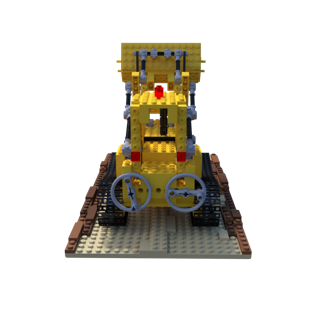

Optimizing /content/kerbl_project3/lego_7000_s2f1ep4x
Output folder: /content/kerbl_project3/lego_7000_s2f1ep4x [22/11 16:40:30]
Tensorboard not available: not logging progress [22/11 16:40:30]
Found transforms_train.json file, assuming Blender data set! [22/11 16:40:30]
Reading Training Transforms [22/11 16:40:30]
Reading Test Transforms [22/11 16:40:34]
Generating random point cloud (100000)... [22/11 16:40:44]
Loading Training Cameras [22/11 16:40:44]
Loading Test Cameras [22/11 16:40:46]
Number of points at initialisation :  100000 [22/11 16:40:48]

Training progress: 100%|██████████| 7000/7000 [01:05<00:00, 106.56it/s, Loss=0.0058736]

[ITER 7000] Saving Gaussians [22/11 16:41:54]

Training complete. [22/11 16:41:56]
Training took 1.48 minutes. Model folder: /content/kerbl_project3/lego_7000_s2f1ep4x
Looking for config file in /content/kerbl_project3/lego_7000_s2f1ep4x/cfg_args
Config file found: /content/kerbl_project3/lego_7000_s2f1ep4x/cfg_args
Rendering /content/kerbl_project3

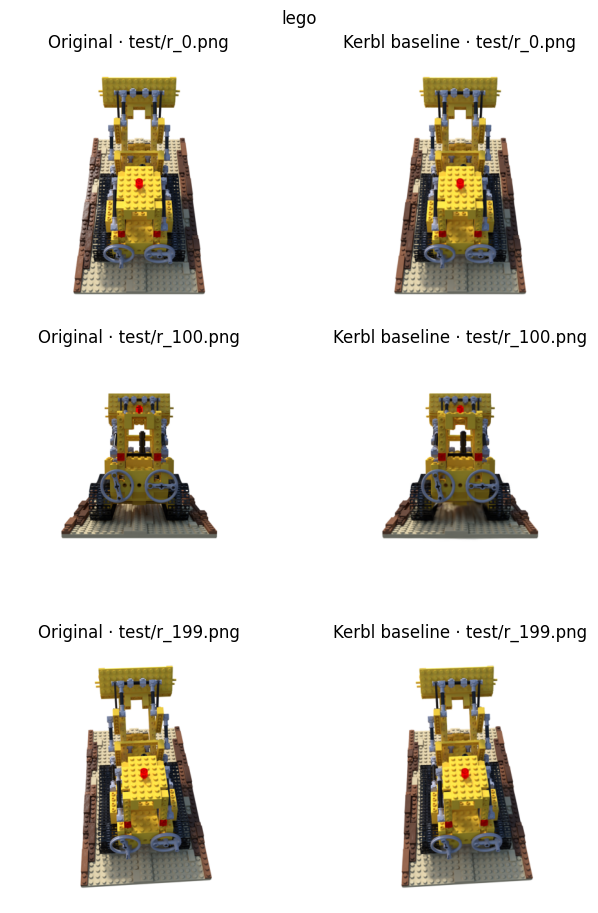

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth

  0%|          | 0.00/528M [00:00<?, ?B/s]
  2%|▏         | 12.1M/528M [00:00<00:04, 127MB/s]
  6%|▌         | 31.3M/528M [00:00<00:03, 171MB/s]
 10%|▉         | 50.7M/528M [00:00<00:02, 186MB/s]
 13%|█▎        | 70.2M/528M [00:00<00:02, 193MB/s]
 17%|█▋        | 89.6M/528M [00:00<00:02, 197MB/s]
 21%|██        | 109M/528M [00:00<00:02, 199MB/s] 
 24%|██▍       | 129M/528M [00:00<00:02, 201MB/s]
 28%|██▊       | 148M/528M [00:00<00:01, 202MB/s]
 32%|███▏      | 168M/528M [00:00<00:01, 203MB/s]
 35%|███▌      | 187M/528M [00:01<00:01, 204MB/s]
 39%|███▉      | 207M/528M [00:01<00:01, 197MB/s]
 43%|████▎     | 226M/528M [00:01<00:01, 200MB/s]
 47%|████▋     | 246M/528M [00:01<00:01, 202MB/s]
 50%|█████     | 266M/528M [00:01<00:01, 204MB/s]
 54%|█████▍    | 286M/528M [00:01<00:01, 205MB/s]
 58%|█████▊    | 306M/528M [00:01<00:01, 206MB/s]
 62%|██████▏   | 325M/5

,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,lego,Kerbl 3DGS,7000,100,1.478,220988,13038292,52.2676,200,400,400,366.3994,NVIDIA L4,2.2.2+cu118,11.8,406.937,33.9955,0.9838,0.0062,0.0149


100 train / 200 test views at 400x400
Model: {'total_splats': 512, 'active_splats': 512, 'total_params': 324096}
iter      1/1000  MSE 0.13418  batch PSNR   8.72 dB  elapsed   0.0 min  ETA   3.7 min
iter    100/1000  MSE 0.07354  batch PSNR  11.33 dB  elapsed   0.2 min  ETA   2.1 min
iter    200/1000  MSE 0.05592  batch PSNR  12.52 dB  elapsed   0.5 min  ETA   1.9 min
iter    300/1000  MSE 0.05183  batch PSNR  12.85 dB  elapsed   0.7 min  ETA   1.7 min
iter    400/1000  MSE 0.04210  batch PSNR  13.76 dB  elapsed   0.9 min  ETA   1.4 min
iter    500/1000  MSE 0.04951  batch PSNR  13.05 dB  elapsed   1.2 min  ETA   1.2 min
iter    600/1000  MSE 0.04427  batch PSNR  13.54 dB  elapsed   1.4 min  ETA   0.9 min
iter    700/1000  MSE 0.04358  batch PSNR  13.61 dB  elapsed   1.7 min  ETA   0.7 min
iter    800/1000  MSE 0.03827  batch PSNR  14.17 dB  elapsed   1.9 min  ETA   0.5 min
iter    900/1000  MSE 0.04778  batch PSNR  13.21 dB  elapsed   2.1 min  ETA   0.2 min
iter   1000/1000  MSE 0.035

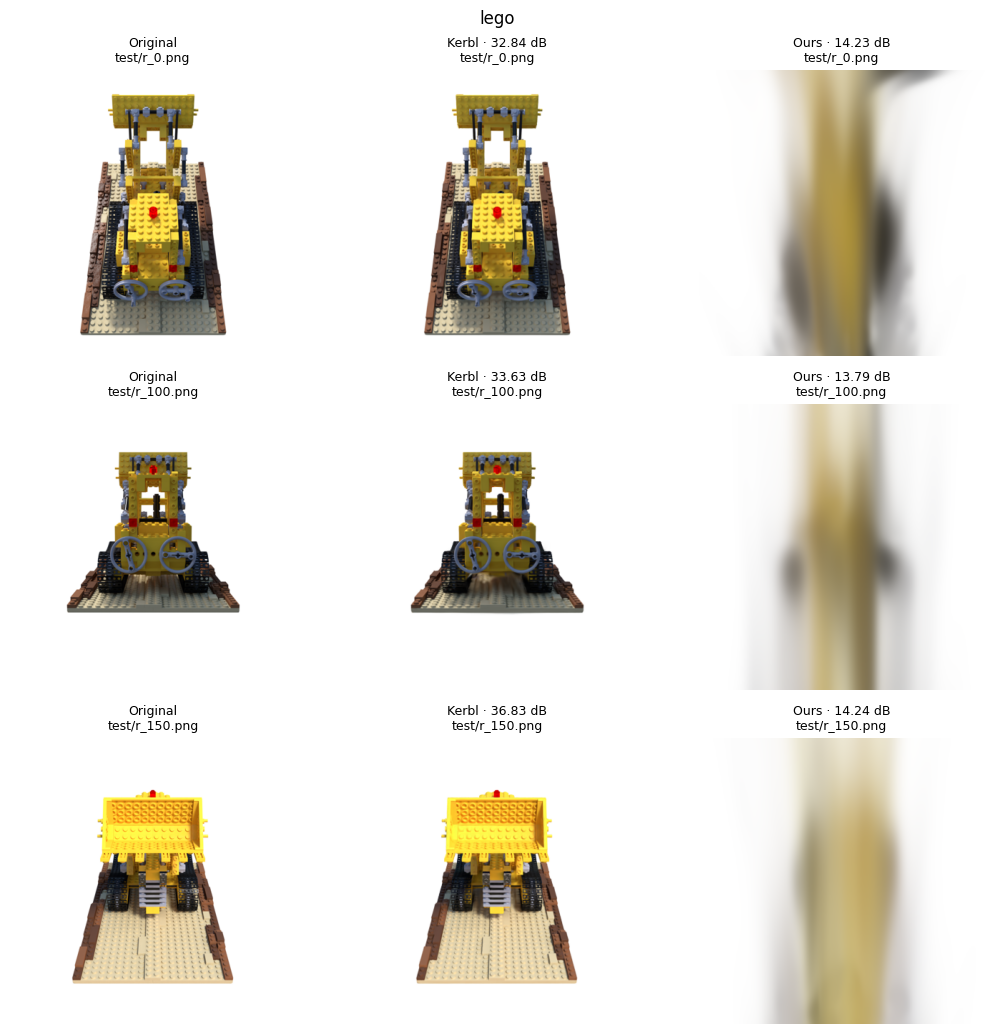

,scene,method,splats,active_splats_opacity_gt_0_01,trainable_parameters,model_MiB,train_minutes,peak_train_torch_allocated_MiB,render_fps,test_views_scored,width,height,PSNR_dB,SSIM,L1,LPIPS_VGG
0,lego,Kerbl 3DGS,220988,215452,13038292,52.2676,1.4780,406.9370,366.3994,4,400,400,35.0318,0.9851,0.0049,0.0141
1,lego,Factorized (ours),512,512,324096,1.2432,2.3736,3934.5928,0.0281,4,400,400,14.1363,0.7477,0.1174,0.3232



===== chair =====


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


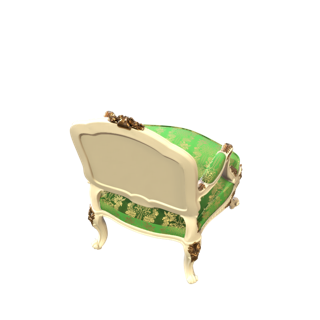

Optimizing /content/kerbl_project3/chair_7000_ac6jixi8
Output folder: /content/kerbl_project3/chair_7000_ac6jixi8 [22/11 16:49:02]
Tensorboard not available: not logging progress [22/11 16:49:02]
Found transforms_train.json file, assuming Blender data set! [22/11 16:49:02]
Reading Training Transforms [22/11 16:49:02]
Reading Test Transforms [22/11 16:49:07]
Generating random point cloud (100000)... [22/11 16:49:16]
Loading Training Cameras [22/11 16:49:16]
Loading Test Cameras [22/11 16:49:17]
Number of points at initialisation :  100000 [22/11 16:49:20]

Training progress: 100%|██████████| 7000/7000 [00:56<00:00, 124.28it/s, Loss=0.0043143]

[ITER 7000] Saving Gaussians [22/11 16:50:17]

Training complete. [22/11 16:50:18]
Training took 1.29 minutes. Model folder: /content/kerbl_project3/chair_7000_ac6jixi8
Looking for config file in /content/kerbl_project3/chair_7000_ac6jixi8/cfg_args
Config file found: /content/kerbl_project3/chair_7000_ac6jixi8/cfg_args
Rendering /content/kerbl_pro

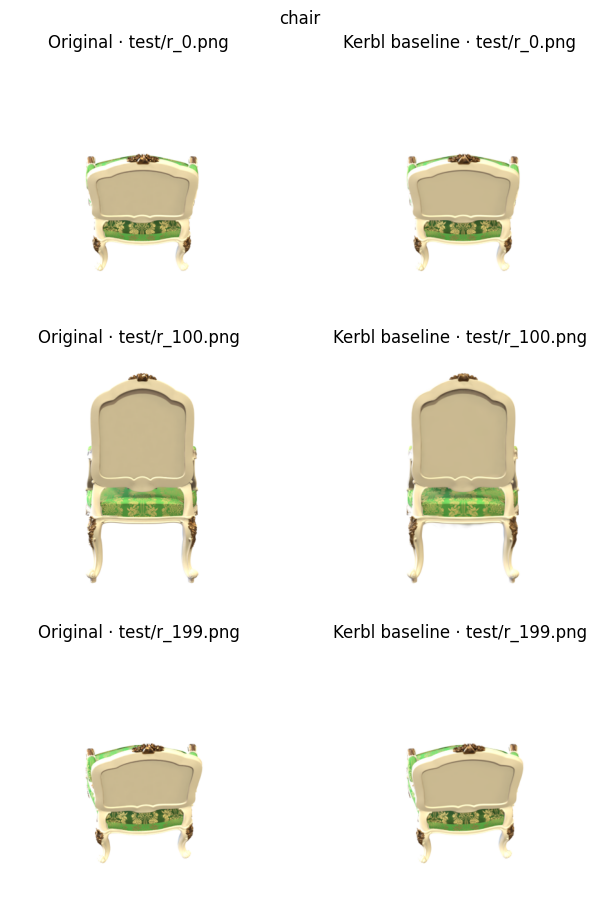

{'PSNR_dB': 36.28104103088379, 'SSIM': 0.9894369834661484, 'L1': 0.004222810479113832, 'LPIPS_VGG': 0.011763918497599661}


,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,chair,Kerbl 3DGS,7000,100,1.2913,138433,8167547,32.7424,200,400,400,445.4775,NVIDIA L4,2.2.2+cu118,11.8,300.4595,36.281,0.9894,0.0042,0.0118


100 train / 200 test views at 400x400
Model: {'total_splats': 512, 'active_splats': 512, 'total_params': 324096}
iter      1/1000  MSE 0.14869  batch PSNR   8.28 dB  elapsed   0.0 min  ETA   3.7 min
iter    100/1000  MSE 0.03821  batch PSNR  14.18 dB  elapsed   0.2 min  ETA   2.1 min
iter    200/1000  MSE 0.02362  batch PSNR  16.27 dB  elapsed   0.5 min  ETA   1.9 min
iter    300/1000  MSE 0.02716  batch PSNR  15.66 dB  elapsed   0.7 min  ETA   1.7 min
iter    400/1000  MSE 0.02363  batch PSNR  16.27 dB  elapsed   0.9 min  ETA   1.4 min
iter    500/1000  MSE 0.02630  batch PSNR  15.80 dB  elapsed   1.2 min  ETA   1.2 min
iter    600/1000  MSE 0.02339  batch PSNR  16.31 dB  elapsed   1.4 min  ETA   0.9 min
iter    700/1000  MSE 0.01909  batch PSNR  17.19 dB  elapsed   1.7 min  ETA   0.7 min
iter    800/1000  MSE 0.02340  batch PSNR  16.31 dB  elapsed   1.9 min  ETA   0.5 min
iter    900/1000  MSE 0.01677  batch PSNR  17.75 dB  elapsed   2.1 min  ETA   0.2 min
iter   1000/1000  MSE 0.014

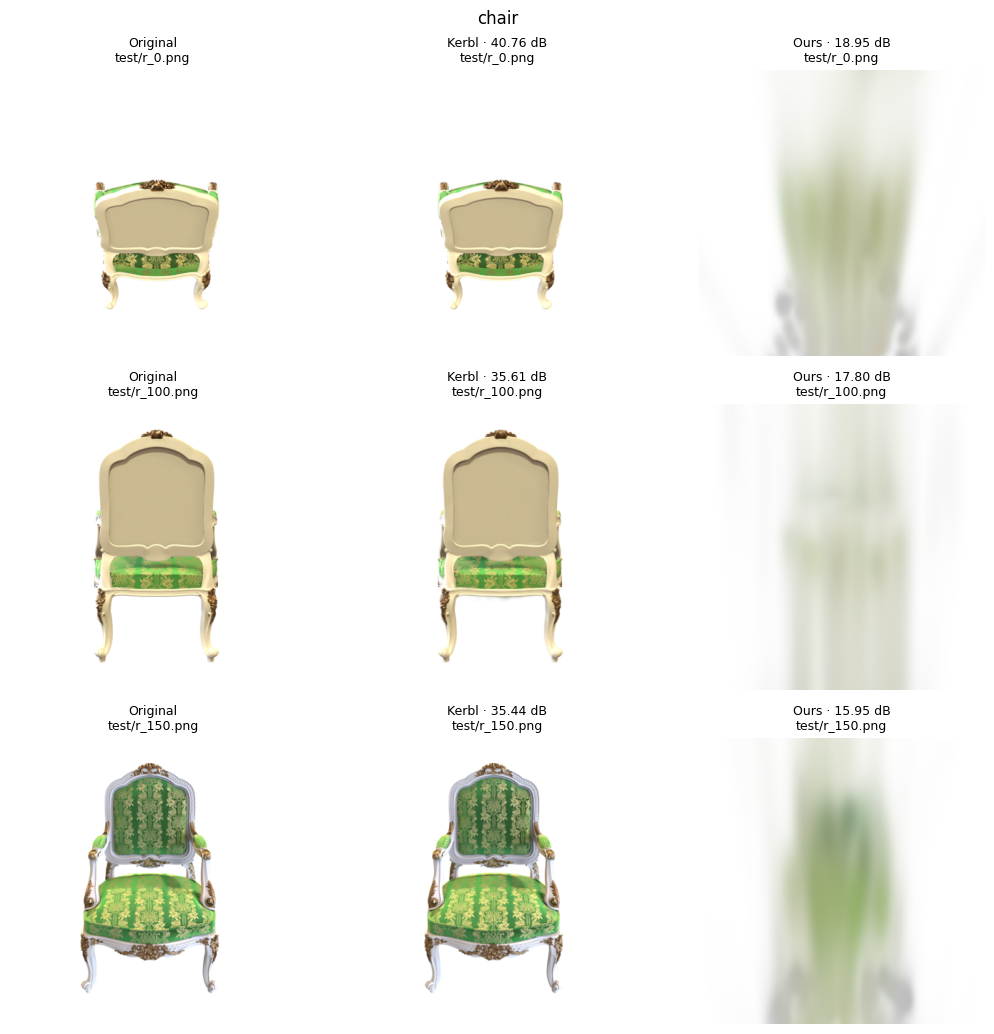

,scene,method,splats,active_splats_opacity_gt_0_01,trainable_parameters,model_MiB,train_minutes,peak_train_torch_allocated_MiB,render_fps,test_views_scored,width,height,PSNR_dB,SSIM,L1,LPIPS_VGG
0,chair,Kerbl 3DGS,138433,132448,8167547,32.7424,1.2913,300.4595,445.4775,4,400,400,36.7987,0.9896,0.0042,0.0116
1,chair,Factorized (ours),512,512,324096,1.2432,2.3741,3934.5928,0.0281,4,400,400,17.1738,0.8188,0.0820,0.2677



===== ficus =====


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 302 files:   0%|          | 0/302 [00:00<?, ?it/s]

train 100 views
test 200 views
Input image dimensions: (800, 800)


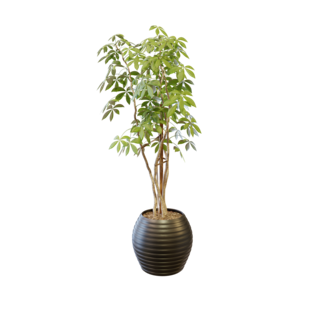

Optimizing /content/kerbl_project3/ficus_7000_jaapyv5h
Output folder: /content/kerbl_project3/ficus_7000_jaapyv5h [22/11 16:57:12]
Tensorboard not available: not logging progress [22/11 16:57:12]
Found transforms_train.json file, assuming Blender data set! [22/11 16:57:12]
Reading Training Transforms [22/11 16:57:12]
Reading Test Transforms [22/11 16:57:17]
Generating random point cloud (100000)... [22/11 16:57:26]
Loading Training Cameras [22/11 16:57:26]
Loading Test Cameras [22/11 16:57:27]
Number of points at initialisation :  100000 [22/11 16:57:30]

Training progress: 100%|██████████| 7000/7000 [00:54<00:00, 129.17it/s, Loss=0.0065516]

[ITER 7000] Saving Gaussians [22/11 16:58:24]

Training complete. [22/11 16:58:26]
Training took 1.25 minutes. Model folder: /content/kerbl_project3/ficus_7000_jaapyv5h
Looking for config file in /content/kerbl_project3/ficus_7000_jaapyv5h/cfg_args
Config file found: /content/kerbl_project3/ficus_7000_jaapyv5h/cfg_args
Rendering /content/kerbl_pro

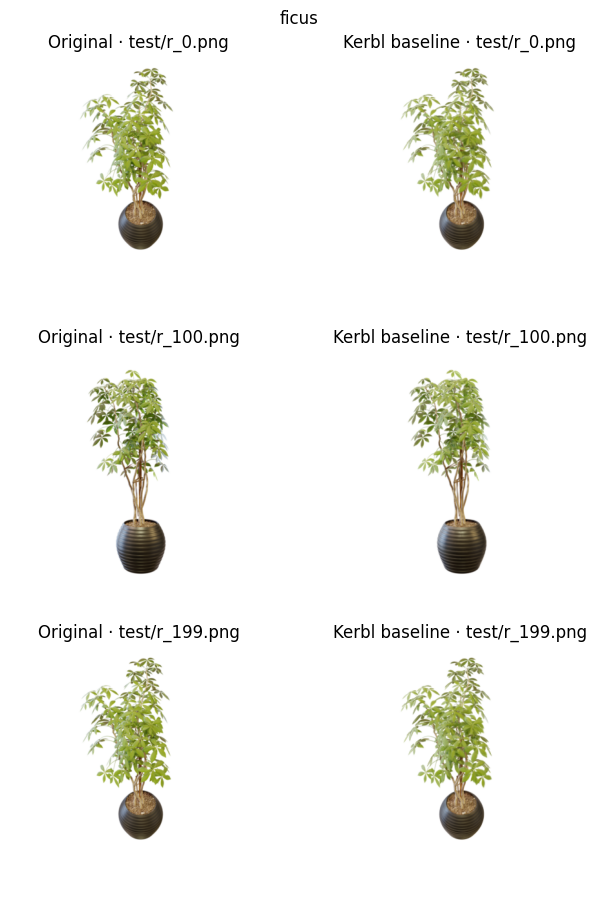

{'PSNR_dB': 31.641892251968383, 'SSIM': 0.9839054372906685, 'L1': 0.006822368237189949, 'LPIPS_VGG': 0.014513666953425854}


,scene,method,iterations,train_views,train_minutes,final_gaussians,trainable_parameters,model_MiB,test_views,width,height,render_fps,gpu,torch,cuda,peak_train_torch_allocated_MiB,PSNR_dB,SSIM,L1,LPIPS_VGG
0,ficus,Kerbl 3DGS,7000,100,1.2544,150339,8870001,35.5583,200,400,400,434.0339,NVIDIA L4,2.2.2+cu118,11.8,295.0425,31.6419,0.9839,0.0068,0.0145


100 train / 200 test views at 400x400
Model: {'total_splats': 512, 'active_splats': 512, 'total_params': 324096}
iter      1/1000  MSE 0.16153  batch PSNR   7.92 dB  elapsed   0.0 min  ETA   3.7 min
iter    100/1000  MSE 0.04917  batch PSNR  13.08 dB  elapsed   0.2 min  ETA   2.1 min
iter    200/1000  MSE 0.02021  batch PSNR  16.95 dB  elapsed   0.5 min  ETA   1.9 min
iter    300/1000  MSE 0.02828  batch PSNR  15.48 dB  elapsed   0.7 min  ETA   1.7 min
iter    400/1000  MSE 0.02219  batch PSNR  16.54 dB  elapsed   0.9 min  ETA   1.4 min
iter    500/1000  MSE 0.03820  batch PSNR  14.18 dB  elapsed   1.2 min  ETA   1.2 min
iter    600/1000  MSE 0.02337  batch PSNR  16.31 dB  elapsed   1.4 min  ETA   0.9 min
iter    700/1000  MSE 0.01869  batch PSNR  17.28 dB  elapsed   1.7 min  ETA   0.7 min
iter    800/1000  MSE 0.01717  batch PSNR  17.65 dB  elapsed   1.9 min  ETA   0.5 min
iter    900/1000  MSE 0.02442  batch PSNR  16.12 dB  elapsed   2.1 min  ETA   0.2 min
iter   1000/1000  MSE 0.026

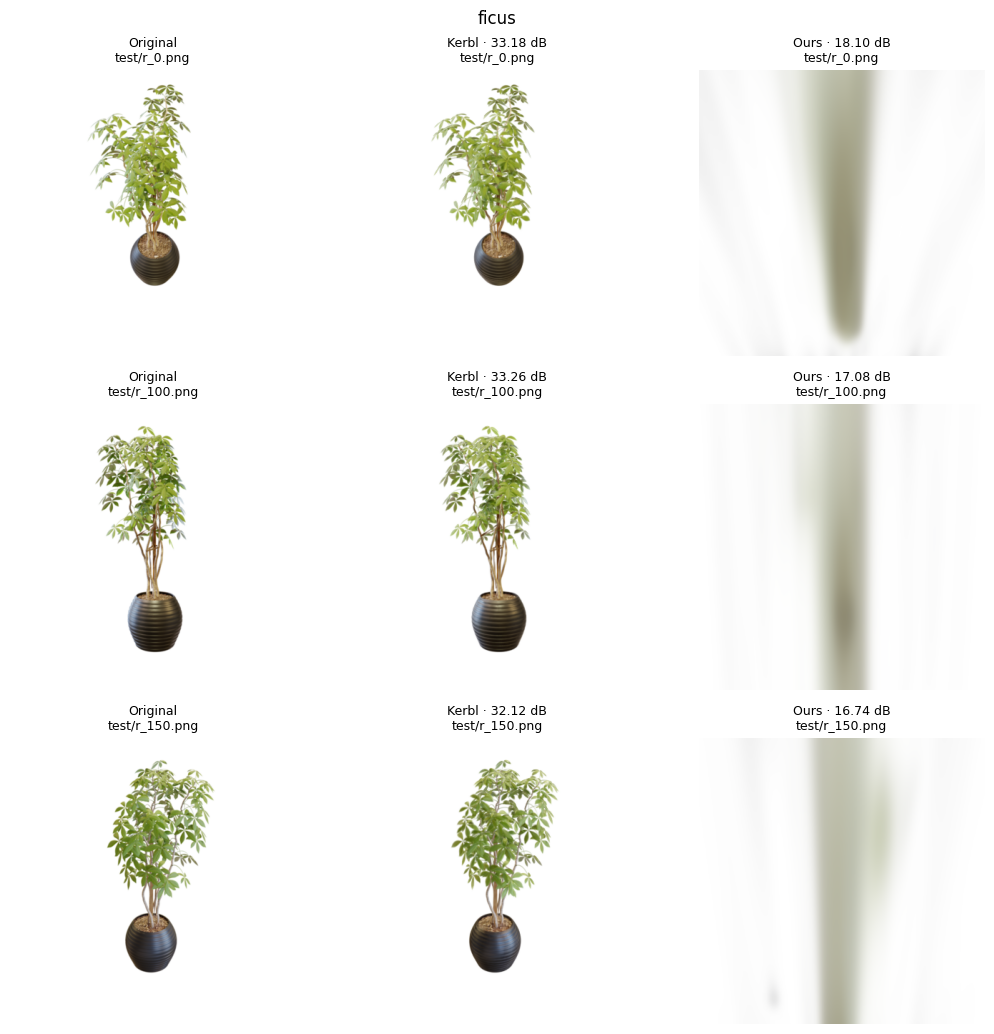

,scene,method,splats,active_splats_opacity_gt_0_01,trainable_parameters,model_MiB,train_minutes,peak_train_torch_allocated_MiB,render_fps,test_views_scored,width,height,PSNR_dB,SSIM,L1,LPIPS_VGG
0,ficus,Kerbl 3DGS,150339,141705,8870001,35.5583,1.2544,295.0425,434.0339,4,400,400,32.6364,0.9861,0.0058,0.0120
1,ficus,Factorized (ours),512,512,324096,1.2432,2.3737,3934.5928,0.0281,4,400,400,17.1681,0.8360,0.0677,0.1954



All scenes (PSNR/SSIM higher = better, L1/LPIPS lower = better):


,scene,method,splats,active_splats_opacity_gt_0_01,trainable_parameters,model_MiB,train_minutes,peak_train_torch_allocated_MiB,render_fps,test_views_scored,width,height,PSNR_dB,SSIM,L1,LPIPS_VGG
0,lego,Kerbl 3DGS,220988.0,215452.0000,13038292.0,52.2676,1.4780,406.9370,366.3994,4.0,400.0,400.0,35.0318,0.9851,0.0049,0.0141
1,lego,Factorized (ours),512.0,512.0000,324096.0,1.2432,2.3736,3934.5928,0.0281,4.0,400.0,400.0,14.1363,0.7477,0.1174,0.3232
2,chair,Kerbl 3DGS,138433.0,132448.0000,8167547.0,32.7424,1.2913,300.4595,445.4775,4.0,400.0,400.0,36.7987,0.9896,0.0042,0.0116
3,chair,Factorized (ours),512.0,512.0000,324096.0,1.2432,2.3741,3934.5928,0.0281,4.0,400.0,400.0,17.1738,0.8188,0.0820,0.2677
4,ficus,Kerbl 3DGS,150339.0,141705.0000,8870001.0,35.5583,1.2544,295.0425,434.0339,4.0,400.0,400.0,32.6364,0.9861,0.0058,0.0120
5,ficus,Factorized (ours),512.0,512.0000,324096.0,1.2432,2.3737,3934.5928,0.0281,4.0,400.0,400.0,17.1681,0.8360,0.0677,0.1954
6,MEAN,Kerbl 3DGS,169920.0,163201.6667,10025280.0,40.1894,1.3412,334.1463,415.3036,NaN,NaN,NaN,34.8223,0.9869,0.0050,0.0126
7,MEAN,Factorized (ours),512.0,512.0000,324096.0,1.2432,2.3738,3934.5928,0.0281,NaN,NaN,NaN,16.1594,0.8008,0.0890,0.2621


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
out_dir = root / f"compare_{ref[:8]}_{data_revision[:8]}_{gpu.replace('/', '-')}_{iterations}_r{resolution_divisor}"
out_dir.mkdir(parents=True, exist_ok=True)
print("Results are saved in:", out_dir, flush=True)

tables, archives = [], []
for scene_name in SCENES:
    sdir = out_dir / scene_name
    base, prop = sdir / "baseline", sdir / "proposed"
    print(f"\n===== {scene_name} =====", flush=True)
    scene, splits = prepare_scene(scene_name)

    # Kerbl baseline
    if (base / "summary.csv").is_file() and (base / "views" / "gt").is_dir():
        print("Reusing completed baseline for", scene_name, flush=True)
    else:
        model, cloud, train_minutes, command = train_scene(scene_name, scene)
        view_dir, report = render_scene(scene_name, model, splits)
        evaluate_scene(scene, model, cloud, view_dir, report)
        bundle = save_scene_results(scene_name, scene, splits, model, report, train_minutes, command)
        if base.exists():
            shutil.rmtree(base)
        shutil.copytree(report, base)
        shutil.copytree(view_dir, base / "views")
        (base / "active.json").write_text(json.dumps(kerbl_active_splats(cloud)))
        os.replace(bundle, sdir / bundle.name)
    archives += sorted(sdir.glob("*_results.zip"))

    # factorized model
    if (prop / "per_view.csv").is_file():
        print("Reusing factorized model for", scene_name, flush=True)
    else:
        prop_views = train_proposed(scene_name, scene, prop)
        same_ground_truth(base / "views", prop_views)
        baseline_python("-c", score_code, prop_views, prop)

    # compare
    tables.append(compare_scene(scene_name, splits, sdir))

comparison = pd.concat(tables, ignore_index=True)
cols = ["PSNR_dB", "SSIM", "L1", "LPIPS_VGG", "splats", "active_splats_opacity_gt_0_01", "trainable_parameters",
        "model_MiB", "train_minutes", "peak_train_torch_allocated_MiB", "render_fps"]
mean_rows = comparison.groupby("method", sort=False)[cols].mean().reset_index()
mean_rows.insert(0, "scene", "MEAN")
comparison = pd.concat([comparison, mean_rows], ignore_index=True)
print("\nAll scenes (PSNR/SSIM higher = better, L1/LPIPS lower = better):")
display(comparison.round(4))

combined = out_dir / ("comparison_" + "_".join(SCENES) + f"_{iterations}_r{resolution_divisor}.zip")
with zipfile.ZipFile(combined, "w", compression=zipfile.ZIP_DEFLATED) as output:
    output.writestr("all_scenes_comparison.csv", comparison.to_csv(index=False))
    output.writestr("proposed_settings.json", json.dumps(PROPOSED, indent=2))
    for scene_name in SCENES:
        sdir = out_dir / scene_name
        for path in sorted(sdir.rglob("*")):
            if path.is_file() and "views" not in path.parts:
                output.write(path, str(path.relative_to(out_dir)))
print("Downloading", combined.name)
files.download(str(combined))
